#### <b>01 eksplorasi data train

In [10]:
# import library
from pathlib import Path
import cv2
import pandas as pd

In [11]:
# overview
root = Path.cwd()
if root.name == "notebook":
    root = root.parent

train_dir = root / "data" / "train"
video_paths = sorted(
    path for path in train_dir.rglob("*")
    if path.is_file() and path.suffix.lower() == ".mov"
)
if not video_paths:
    raise FileNotFoundError(f"Tidak ada video MOV di {train_dir}")

records = []
for video_path in video_paths:
    relative_path = video_path.relative_to(train_dir)
    class_name, subject = relative_path.parts[:2]
    camera, action = video_path.stem.split("_", 1)

    capture = cv2.VideoCapture(str(video_path))
    try:
        fps = capture.get(cv2.CAP_PROP_FPS)
        frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        valid_metadata = capture.isOpened() and fps > 0 and frames > 0
    finally:
        capture.release()

    records.append({
        "subject": subject,
        "class": class_name,
        "label": {"normal": 0, "cheat": 1}[class_name],
        "action": action,
        "camera": camera,
        "video": relative_path.as_posix(),
        "frames": frames if valid_metadata else None,
        "fps": fps if valid_metadata else None,
        "duration_s": frames / fps if valid_metadata else None,
    })

videos = pd.DataFrame(records)
unreadable = videos.loc[videos["fps"].isna(), "video"]
print(f"Video: {len(videos)} | ID subjek unik: {videos['subject'].nunique()}")
print(f"Video tanpa metadata FPS atau durasi: {len(unreadable)}")
if not unreadable.empty:
    print(unreadable.to_string(index=False))

Video: 416 | ID subjek unik: 26
Video tanpa metadata FPS atau durasi: 0


<i style="color: red;">tidak ada video yang error</i>

In [12]:
# review per class
by_class = videos.groupby("class").agg(
    subjects=("subject", "nunique"),
    actions=("action", "nunique"),
    videos=("video", "size"),
    duration_min_s=("duration_s", "min"),
    duration_max_s=("duration_s", "max"),
    fps_min=("fps", "min"),
    fps_max=("fps", "max"),
)
print(by_class.round(3).to_string())
print()
for class_name, group in videos.groupby("class"):
    print(f"{class_name}: {', '.join(sorted(group['action'].unique()))}")


        subjects  actions  videos  duration_min_s  duration_max_s  fps_min  fps_max
class                                                                              
cheat         26        4     208          13.567          18.617   29.972     30.0
normal        26        4     208          14.380          18.483   29.972     30.0

cheat: Looking_Under_the_Desk, Reading_Hidden_Notes, Repeated_Peeking, Using_Smartwatch
normal: Checking_Smartwatch, Looking_Around, Thinking, Writing_Answers


<i style="color: red;">fps semua video sekitar 30</i>

In [13]:
# cek jumlah aksi dan video, durasi, serta fps per subjek dan kelas
by_subject = videos.groupby(["subject", "class"]).agg(
    actions=("action", "nunique"),
    videos=("video", "size"),
    duration_min_s=("duration_s", "min"),
    duration_mean_s=("duration_s", "mean"),
    duration_max_s=("duration_s", "max"),
    fps_min=("fps", "min"),
    fps_mean=("fps", "mean"),
    fps_max=("fps", "max"),
).reset_index()

by_subject["subject_number"] = by_subject["subject"].str.extract(r"(\d+)$")[0].astype(int)
by_subject = by_subject.sort_values(["subject_number", "class"]).drop(columns="subject_number")
actions_per_subject = videos.groupby("subject")["action"].nunique()
print("Distribusi jumlah jenis aksi per subjek (jumlah aksi: jumlah subjek)")
print(actions_per_subject.value_counts().sort_index().to_string())
print()
print(by_subject.round(3).to_string(index=False))


Distribusi jumlah jenis aksi per subjek (jumlah aksi: jumlah subjek)
action
8    26

   subject  class  actions  videos  duration_min_s  duration_mean_s  duration_max_s  fps_min  fps_mean  fps_max
 subject_1  cheat        4       8          13.567           15.215          16.315   29.972    29.987     30.0
 subject_1 normal        4       8          15.133           15.836          17.048   29.973    29.987     30.0
 subject_2  cheat        4       8          15.880           16.436          17.748   29.972    29.987     30.0
 subject_2 normal        4       8          15.867           16.224          16.715   29.973    29.987     30.0
 subject_3  cheat        4       8          15.333           15.698          16.147   29.974    29.987     30.0
 subject_3 normal        4       8          14.800           15.790          17.900   29.974    29.987     30.0
 subject_4  cheat        4       8          14.833           15.953          16.733   29.973    29.987     30.0
 subject_4 normal  

In [14]:
# Ganti ID ini untuk melihat durasi dan FPS setiap video subjek lain.
selected_subject = "subject_1"
details = videos.loc[videos["subject"].eq(selected_subject)].sort_values(
    ["class", "action", "camera"]
)
print(details[["class", "action", "camera", "frames", "duration_s", "fps"]]
      .round(3).to_string(index=False))

 class                 action camera  frames  duration_s    fps
 cheat Looking_Under_the_Desk  front     407      13.567 30.000
 cheat Looking_Under_the_Desk   side     446      14.880 29.973
 cheat   Reading_Hidden_Notes  front     463      15.433 30.000
 cheat   Reading_Hidden_Notes   side     488      16.280 29.975
 cheat       Repeated_Peeking  front     443      14.767 30.000
 cheat       Repeated_Peeking   side     489      16.315 29.972
 cheat       Using_Smartwatch  front     448      14.933 30.000
 cheat       Using_Smartwatch   side     466      15.547 29.974
normal    Checking_Smartwatch  front     455      15.167 30.000
normal    Checking_Smartwatch   side     491      16.382 29.973
normal         Looking_Around  front     454      15.133 30.000
normal         Looking_Around   side     470      15.680 29.974
normal               Thinking  front     480      16.000 30.000
normal               Thinking   side     511      17.048 29.974
normal        Writing_Answers  front    

#### <b>02 eda

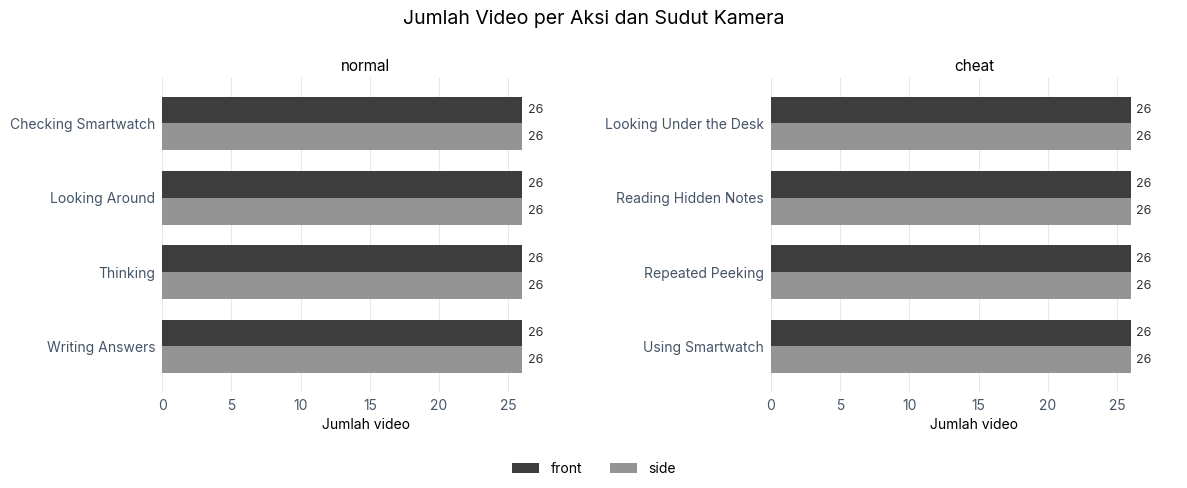

In [ ]:
# cek jumlah video per aksi dan sudut kamera
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import MultipleLocator

font_manager.fontManager.addfont(root / "notebook" / "fonts" / "Inter.ttf")
camera_colors = {"front": "#3d3d3d", "side": "#949494"}
action_counts = videos.groupby(["class", "action", "camera"]).size().unstack(fill_value=0)

with plt.rc_context({"font.family": ["Inter", "DejaVu Sans"], "font.size": 10}):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, layout="constrained")
    fig.get_layout_engine().set(rect=(0.01, 0.03, 0.98, 0.83), wspace=0.06)
    fig.suptitle("Jumlah Video per Aksi dan Sudut Kamera", fontsize=14, y=0.95)

    for ax, class_name in zip(axes, ("normal", "cheat")):
        counts = action_counts.loc[class_name]
        counts = counts.rename(index=lambda action: action.replace("_", " "))
        counts.plot.barh(ax=ax, color=camera_colors, width=0.72, legend=False)
        for bars in ax.containers:
            ax.bar_label(bars, padding=4, fontsize=9, color="#333333")

        ax.invert_yaxis()
        ax.set_title(class_name, fontsize=11, pad=5)
        ax.set(xlabel="Jumlah video", ylabel="", xlim=(0, action_counts.max().max() * 1.13))
        ax.xaxis.set_major_locator(MultipleLocator(5))
        ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
        ax.tick_params(length=0, pad=5, colors="#475569")
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#e8e5ec", linewidth=0.75)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)

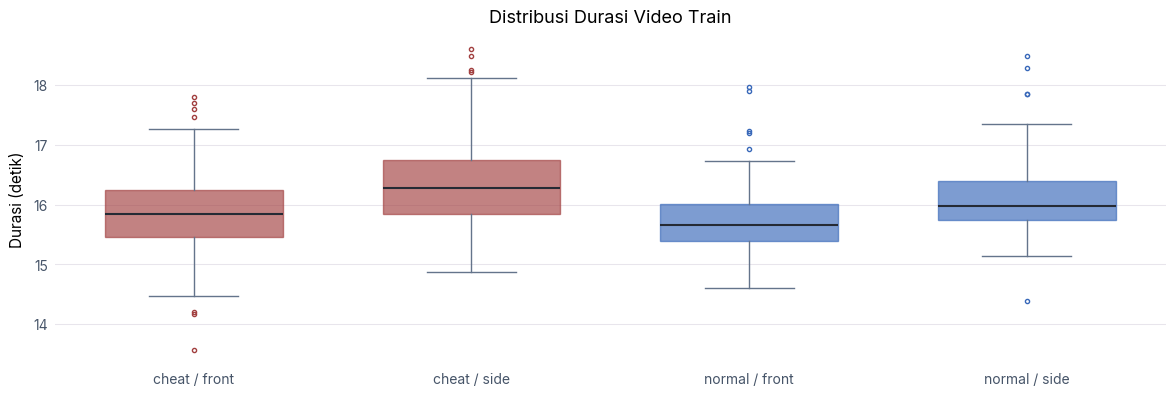

In [ ]:
# bandingkan durasi video antar kelas dan sudut kamera
from matplotlib import font_manager
from matplotlib.ticker import MultipleLocator

font_manager.fontManager.addfont(root / "notebook" / "fonts" / "Inter.ttf")

with plt.rc_context({
    "font.family": ["Inter", "DejaVu Sans"],
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
}):
    duration_box_fig, box_ax = plt.subplots(figsize=(12, 5), layout="constrained")
    duration_box_fig.get_layout_engine().set(rect=(0.015, 0.035, 0.97, 0.77))
    colors = {"normal": "#3868b9", "cheat": "#A24040"}
    groups = videos.groupby(["class", "camera"], sort=True)
    positions = range(1, groups.ngroups + 1)
    labels = []
    for position, ((class_name, camera), group) in zip(positions, groups):
        labels.append(f"{class_name} / {camera}")
        color = colors[class_name]
        box_ax.boxplot(
            group["duration_s"].dropna(), positions=[position], widths=0.64,
            patch_artist=True, manage_ticks=False,
            boxprops={"facecolor": color, "edgecolor": color, "alpha": 0.65},
            medianprops={"color": "#252a34", "linewidth": 1.5},
            whiskerprops={"color": "#64748b"},
            capprops={"color": "#64748b"},
            flierprops={"marker": "o", "markersize": 3, "markeredgecolor": color},
        )

    box_ax.set_xticks(positions, labels)
    box_ax.set_xlim(0.5, groups.ngroups + 0.5)
    box_ax.set_title("Distribusi Durasi Video Train", fontweight="medium", pad=8)
    box_ax.set_ylabel("Durasi (detik)", labelpad=6)
    box_ax.yaxis.set_major_locator(MultipleLocator(1))
    box_ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    box_ax.tick_params(length=0, pad=5, colors="#475569")
    box_ax.set_axisbelow(True)
    box_ax.grid(axis="y", color="#e8e5ec", linewidth=0.75)


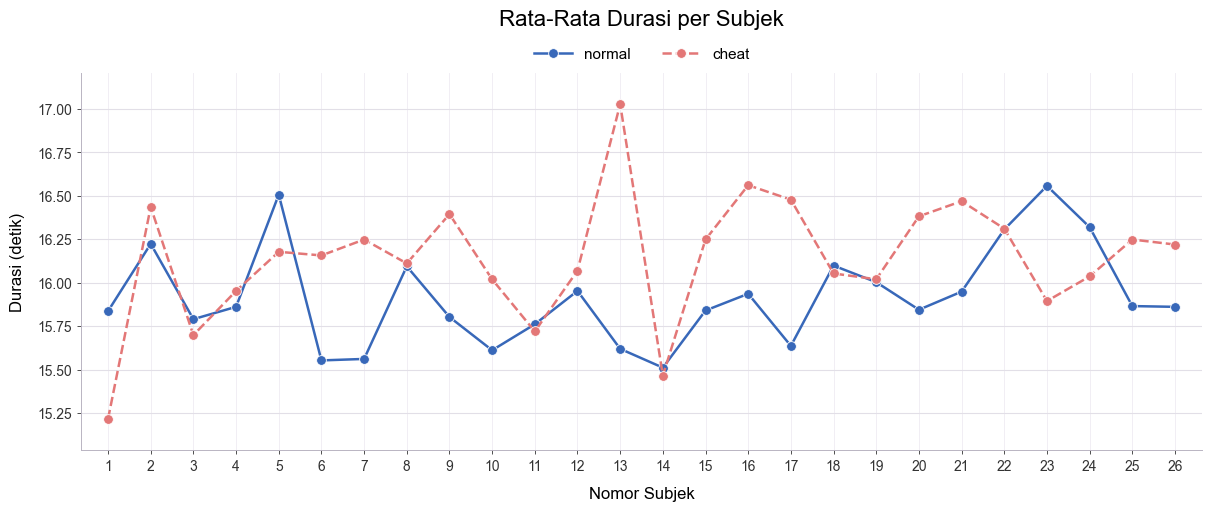

In [116]:
# cek durasi rata-rata per subjek
from matplotlib import font_manager

font_manager.fontManager.addfont(root / "notebook" / "fonts" / "Inter.ttf")

with plt.rc_context({
    "font.family": ["Arial", "DejaVu Sans"],
    "axes.titlesize": 16,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
}):
    subject_duration = by_subject.pivot(index="subject", columns="class", values="duration_mean_s")
    subject_duration = subject_duration.reindex(by_subject["subject"].drop_duplicates())
    subject_numbers = subject_duration.index.str.removeprefix("subject_")

    duration_fig, duration_ax = plt.subplots(
        figsize=(12, 5), layout="constrained", facecolor="white",
    )
    duration_ax.spines[["top", "right"]].set_visible(False)
    duration_ax.spines[["left", "bottom"]].set_color("#b9b4c2")
    duration_ax.spines[["left", "bottom"]].set_linewidth(0.7)
    duration_ax.tick_params(length=3, width=0.6, colors="#333333")

    duration_ax.set_axisbelow(True)

    for class_name, color, linestyle in (
        ("normal", "#3868b9", "-"), ("cheat", "#e37777", "--"),
    ):
        duration_ax.plot(
            subject_numbers, subject_duration[class_name], color=color,
            linewidth=1.8, linestyle=linestyle, label=class_name,
            marker="o", markersize=7, markeredgecolor="white", markeredgewidth=0.6,
        )
    duration_ax.set_title("Rata-Rata Durasi per Subjek", loc="center", fontweight="medium", pad=34)
    duration_ax.set(xlabel="Nomor Subjek", ylabel="Durasi (detik)")
    duration_ax.margins(x=0.025, y=0.10)
    duration_ax.xaxis.labelpad = 9
    duration_ax.yaxis.labelpad = 9
    duration_ax.legend(
        ncol=2, frameon=False, loc="lower center",
        bbox_to_anchor=(0.5, 1.015), borderaxespad=0, handlelength=2.5,
    )

    duration_ax.grid(True, axis="y", color="#e2dfe7", linewidth=0.8)
    duration_ax.grid(True, axis="x", color="#f0edf3", linewidth=0.65)

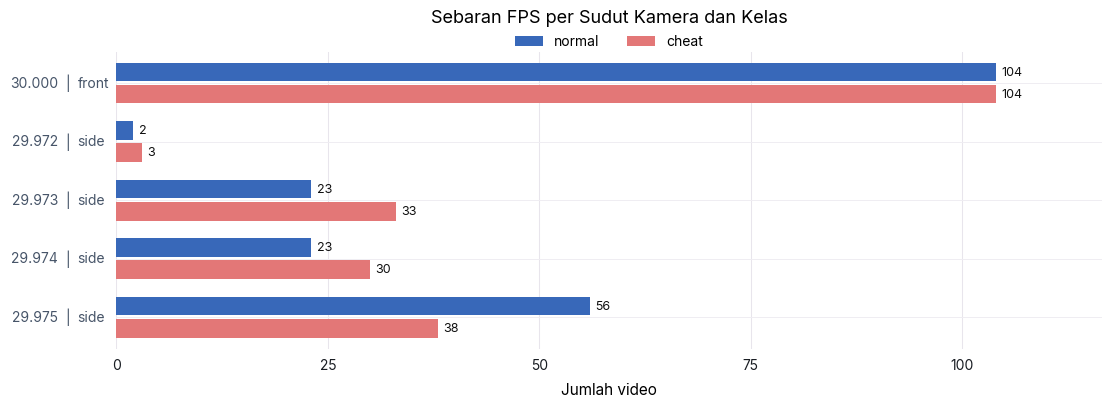

In [115]:
# cek sebaran fps per sudut kamera dan kelas
from matplotlib import font_manager
from matplotlib.ticker import MultipleLocator

font_manager.fontManager.addfont(root / "notebook" / "fonts" / "Inter.ttf")

with plt.rc_context({
    "font.family": ["Inter", "DejaVu Sans"],
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
}):
    fps_counts = (
        videos.assign(fps_group=videos["fps"].round(3))
        .groupby(["camera", "fps_group", "class"])
        .size()
        .unstack("class", fill_value=0)
        .reindex(columns=["normal", "cheat"], fill_value=0)
    )
    camera_order = {"front": 0, "side": 1}
    fps_counts = fps_counts.sort_index(
        level="camera", key=lambda cameras: cameras.map(camera_order)
    )
    rows = range(len(fps_counts))

    fps_fig, fps_ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
    fps_fig.get_layout_engine().set(rect=(0, 0.06, 1, 0.88))
    for class_name, offset, color in (
        ("normal", -0.19, "#3868b9"), ("cheat", 0.19, "#e37777"),
    ):
        bars = fps_ax.barh(
            [row + offset for row in rows], fps_counts[class_name],
            height=0.32, color=color, label=class_name,
        )
        fps_ax.bar_label(bars, padding=4, fontsize=9, color="#111111")
    fps_ax.set_yticks(rows, labels=[""] * len(fps_counts))
    for row, (camera, fps) in enumerate(fps_counts.index):
        for text, offset, alignment in (
            (f"{fps:.3f}", -42, "right"),
            ("|", -35, "center"),
            (camera, -28, "left"),
        ):
            fps_ax.annotate(
                text, (0, row), xycoords=fps_ax.get_yaxis_transform(),
                xytext=(offset, 0), textcoords="offset points",
                ha=alignment, va="center", fontsize=10, color="#475569",
                annotation_clip=False,
            )
    fps_ax.invert_yaxis()
    fps_ax.margins(y=0.04)
    fps_ax.set_title("Sebaran FPS per Sudut Kamera dan Kelas", loc="center", fontweight="medium", pad=21)
    fps_ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0, borderpad=0.2, ncol=2, frameon=False, fontsize=10)
    fps_ax.set_xlabel("Jumlah video", labelpad=7)
    fps_ax.set_xlim(0, fps_counts.to_numpy().max() * 1.12)
    fps_ax.xaxis.set_major_locator(MultipleLocator(25))
    fps_ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    fps_ax.tick_params(length=0, pad=7, colors="#191D23")
    fps_ax.set_axisbelow(True)
    fps_ax.grid(axis="x", color="#e8e5ec", linewidth=0.75)
    fps_ax.grid(axis="y", color="#efedf2", linewidth=0.7)

#### 03 eksplorasi data test

Satu folder mewakili satu sekuens. Kolom label pada template submission hanya contoh isian. EDA ini memeriksa struktur file dan menampilkan cuplikan dalam urutan waktu.

In [117]:
# cek jumlah frame, urutan file, resolusi, dan ukuran tiap sekuens test
from collections import Counter
from pathlib import Path

import pandas as pd
from PIL import Image

test_root = Path.cwd()
if test_root.name == "notebook":
    test_root = test_root.parent
test_dir = test_root / "data" / "test"
template = pd.read_csv(test_root / "data" / "sample_submission.csv", dtype={"id": str})
expected_numbers = list(range(1, 31))
frame_sizes = {number: [] for number in expected_numbers}
test_records = []
resolutions = Counter()
header_errors = []

for folder in sorted(p for p in test_dir.iterdir() if p.is_dir()):
    files = sorted(p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg"})
    numbers = sorted(int(p.stem) for p in files if p.stem.isdigit())
    total_bytes = 0
    for frame in files:
        size_bytes = frame.stat().st_size
        total_bytes += size_bytes
        if frame.stem.isdigit() and int(frame.stem) in frame_sizes:
            frame_sizes[int(frame.stem)].append(size_bytes / 1024)
        try:
            with Image.open(frame) as img:
                resolutions[img.size] += 1
        except OSError:
            header_errors.append(frame.relative_to(test_dir).as_posix())
    test_records.append({
        "id": folder.name, "frames": len(files),
        "urutan_lengkap": len(files) == 30 and numbers == expected_numbers,
        "ukuran_mib": total_bytes / 1024**2,
    })

test_sequences = pd.DataFrame(test_records).set_index("id")
missing_ids = set(template["id"]) - set(test_sequences.index)
extra_ids = set(test_sequences.index) - set(template["id"])
print(f"Sekuens: {len(test_sequences):,} | Total frame JPG: {test_sequences['frames'].sum():,}")
print(f"ID template tanpa folder: {len(missing_ids)} | Folder di luar template: {len(extra_ids)}")
print(f"ID duplikat di template: {template['id'].duplicated().sum()}")
print(f"Sekuens dengan nomor frame 01-30 lengkap: {test_sequences['urutan_lengkap'].sum():,}")
print(f"Header gambar gagal dibaca: {len(header_errors)}")
for (width, height), count in resolutions.most_common():
    print(f"Resolusi {width} x {height}: {count:,} frame")
print(test_sequences.head().round(2).to_string())

Sekuens: 1,515 | Total frame JPG: 45,450
ID template tanpa folder: 0 | Folder di luar template: 0
ID duplikat di template: 0
Sekuens dengan nomor frame 01-30 lengkap: 1,515
Header gambar gagal dibaca: 0
Resolusi 640 x 360: 45,450 frame
                frames  urutan_lengkap  ukuran_mib
id                                                
test_seq_00001      30            True        1.87
test_seq_00002      30            True        1.86
test_seq_00003      30            True        1.82
test_seq_00004      30            True        1.81
test_seq_00005      30            True        1.84


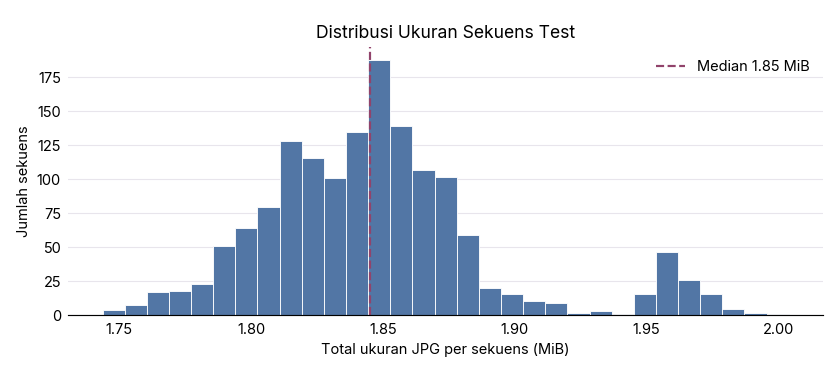

In [118]:
# lihat sebaran total ukuran file jpg per sekuens
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_manager.fontManager.addfont(test_root / "notebook" / "fonts" / "Inter.ttf")
with plt.rc_context({"font.family": ["Inter", "DejaVu Sans"], "font.size": 10}):
    sizes = test_sequences["ukuran_mib"]
    fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
    fig.get_layout_engine().set(rect=(0.015, 0.045, 0.97, 0.9))
    ax.hist(sizes, bins="fd", color="#5276a5", edgecolor="white", linewidth=0.6)
    ax.axvline(sizes.median(), color="#91436b", linestyle="--",
               label=f"Median {sizes.median():.2f} MiB")
    ax.set(title="Distribusi Ukuran Sekuens Test", xlabel="Total ukuran JPG per sekuens (MiB)",
           ylabel="Jumlah sekuens")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(length=0, pad=5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e8e5ec", linewidth=0.75)
    ax.legend(frameon=False)
    plt.show()

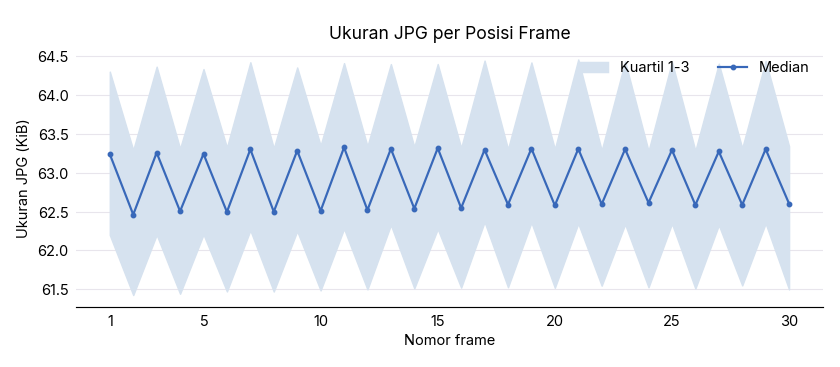

In [119]:
# bandingkan ukuran frame jpg menurut posisinya dalam sekuens
# garis menunjukkan median, area berwarna mencakup 50% frame di tengah
size_quantiles = pd.DataFrame({
    number: pd.Series(sizes_kib, dtype=float).quantile([0.25, 0.50, 0.75])
    for number, sizes_kib in frame_sizes.items()
})
with plt.rc_context({"font.family": ["Inter", "DejaVu Sans"], "font.size": 10}):
    fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
    fig.get_layout_engine().set(rect=(0.015, 0.04, 0.97, 0.9))
    ax.fill_between(expected_numbers, size_quantiles.loc[0.25], size_quantiles.loc[0.75],
                    color="#d6e2ef", label="Kuartil 1-3")
    ax.plot(expected_numbers, size_quantiles.loc[0.50], color="#3868b9",
            marker="o", markersize=3, label="Median")
    ax.set(title="Ukuran JPG per Posisi Frame", xlabel="Nomor frame", ylabel="Ukuran JPG (KiB)")
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(length=0, pad=5)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#e8e5ec", linewidth=0.75)
    ax.legend(frameon=False, ncol=2)
    plt.show()

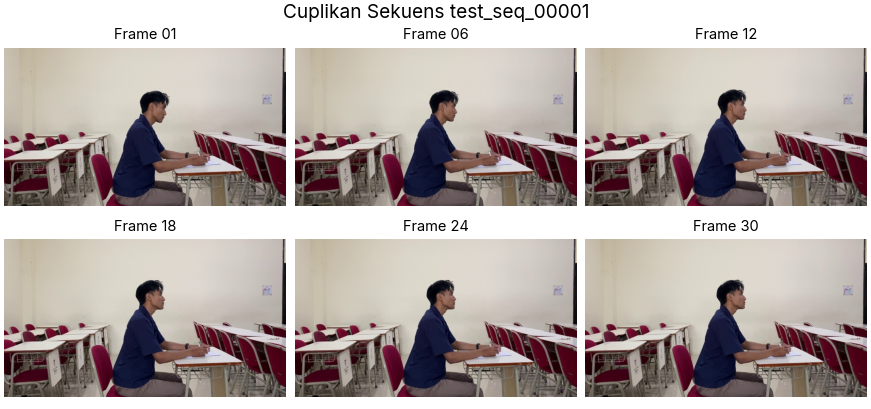

In [120]:
# lihat contoh frame secara kronologis dari satu sekuens test
selected_test_id = template["id"].iloc[0]
frame_numbers = [1, 6, 12, 18, 24, 30]
with plt.rc_context({"font.family": ["Inter", "DejaVu Sans"], "font.size": 10}):
    fig, axes = plt.subplots(2, 3, figsize=(8.3, 3.9), layout="constrained")
    fig.suptitle(f"Cuplikan Sekuens {selected_test_id}", fontsize=13)
    for ax, number in zip(axes.flat, frame_numbers):
        frame_path = test_dir / selected_test_id / f"{number:02d}.jpg"
        with Image.open(frame_path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"Frame {number:02d}", fontsize=10)
        ax.set_axis_off()
    plt.show()